In [1]:
from pathlib import Path
from copy import deepcopy
import json
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import gaussian_filter
import torch
from torchvision.models import efficientnet_b0


In [2]:
IMAGE_ROOT = Path('origin')
METADATA_CSV = Path('expw_subset_metadata_comp90051.csv')
OUTPUT = Path('efficientnet_results')

SEED, IMAGE_SIZE, BATCH_SIZE, EPOCHS = 90051, 128, 32, 2
MASK_FILL, BLUR_SIGMA, NOISE_STD = 128, 1.0, 0.05
LEARNING_RATES = [1e-5, 1e-4, 1e-3]
CONDITIONS = ['clean', 'upper_mask', 'lower_mask', 'blur', 'noise']
CLASS_NAMES = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(SEED)

# Fixed ImageNet channel normalisation (only for efficientnet-b0)
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device)[:, None, None]
STD = torch.tensor([0.229, 0.224, 0.225], device=device)[:, None, None]
print('Device:', device)


Device: cpu


In [3]:
# Cropping the face from each image
# Keep the subset row order
df = pd.read_csv(METADATA_CSV)
labels = df['correct_facial_class'].to_numpy(dtype=int)
faces = np.empty((len(df), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
for i, row in enumerate(df.itertuples(index=False)):
    box = (int(row.left), int(row.top), int(row.right), int(row.bottom))
    with Image.open(IMAGE_ROOT / row.original_image_name) as image:
        # Use RGB crop and optional BILINEAR resize, set images to 224x224 pixels
        faces[i] = np.asarray(image.convert('RGB').crop(box).resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR))
print('Samples:', len(df))


Samples: 14935


In [4]:
# Getting the shared CV splits for the team
def split_rows(y, k):
    # The fixed seed makes this function repeatable for the same input labels
    rng = np.random.default_rng(SEED)
    # Store the fold number assigned to each row
    fold_id = np.empty(len(y), dtype=int)
    offset = 0
    # Handle each emotion separately to keep similar class proportions (stratified)
    for label in np.unique(y):
        # Find and shuffle the row positions belonging to this emotion
        rows = np.flatnonzero(y == label)
        rng.shuffle(rows)
        # Assign rows in turn to folds 0, 1, ..., k-1
        fold_id[rows] = (np.arange(len(rows)) + offset) % k
        # Start the next class at the next fold to balance total fold sizes
        offset = (offset + len(rows)) % k
    # Hold out fold f for validation in inner CV and for testing in outer CV, and all other folds for training
    return [(np.flatnonzero(fold_id != f), np.flatnonzero(fold_id == f)) for f in range(k)]

# Build inner splits within each outer training set
outer_folds, inner_folds = [], []
for fold, (train, test) in enumerate(split_rows(labels, 10), 1):
    outer_folds.append(dict(fold=fold, train_indices=train.tolist(), test_indices=test.tolist()))
    # Create 3 inner splits using only this outer training set for tuning
    for inner_fold, (a, b) in enumerate(split_rows(labels[train], 3), 1):
        # Convert inner positions back to the original CSV rows
        inner_folds.append(dict(outer_fold=fold, inner_fold=inner_fold,
                               train_indices=train[a].tolist(), validation_indices=train[b].tolist()))

# Save both JSON files for reproducing and keeping training validation, and testing sets consistent
folder = Path('shared_cv_manual')
folder.mkdir(exist_ok=True)
for name, splits in [('Outer_10-fold_CV_splits.json', outer_folds),
                     ('Inner_3-fold_CV_splits.json', inner_folds)]:
    (folder/name).write_text(json.dumps(splits))


In [5]:
# Create image conditions, baseline, upper_mask, lower_mask, Gaussian blur, Gaussian noise
def change_image(image, condition, row):
    # Every condition starts from the same clean image (baseline), scaled to [0, 1]
    x = image.astype(np.float32) / 255
    # Set up the mask location
    middle = x.shape[0] // 2
    if condition == 'upper_mask':
        x[:middle] = MASK_FILL / 255
    elif condition == 'lower_mask':
        x[middle:] = MASK_FILL / 255
    elif condition == 'blur':
        # Blur the height and width only
        x = gaussian_filter(x, sigma=(BLUR_SIGMA, BLUR_SIGMA, 0))
    elif condition == 'noise':
        # Give each row the same noise in every fold, keep consistent
        rng = np.random.default_rng([SEED, int(row)])
        x = np.clip(x + rng.normal(0, NOISE_STD, x.shape).astype(np.float32), 0, 1)
    return x

# Replace the ImageNet classifier with seven expression outputs
template = efficientnet_b0(weights='IMAGENET1K_V1')
template.classifier[1] = torch.nn.Linear(template.classifier[1].in_features, 7)
total_parameters = sum(p.numel() for p in template.parameters())

# Freeze the early modules and cache their outputs
prefix = template.features[:-2].to(device).eval().requires_grad_(False)

# Keep the last two feature modules and classifier for training
template.features = template.features[-2:]

# Count parameters in the remaining model
trainable_parameters = sum(p.numel() for p in template.parameters())
print('Total parameters:', total_parameters, '| trainable:', trainable_parameters)

# Store one feature tensor for each image condition
frozen_features = {}

# Calculate fixed features without recording a gradient graph
with torch.no_grad():
    for condition in CONDITIONS:
        print('Preparing fixed features:', condition, flush=True)
        parts = []
        for start in range(0, len(df), BATCH_SIZE):
            rows = range(start, min(start+BATCH_SIZE, len(df)))
            images = np.stack([change_image(faces[i], condition, i) for i in rows])
            # PyTorch image layout: batch, channels, height, width
            x = torch.from_numpy(images.transpose(0, 3, 1, 2)).to(device)
            # Normalise before applying the fixed prefix
            parts.append(prefix((x-MEAN)/STD).cpu())
            if start == 0 or (start+BATCH_SIZE) % 1000 < BATCH_SIZE or rows.stop == len(df):
                print(' ', rows.stop, '/', len(df), flush=True)
        frozen_features[condition] = torch.cat(parts)
# Release temporary arrays after caching
del prefix, faces, parts, images, x


Total parameters: 4016515 | trainable: 1138359
Preparing fixed features: clean
  32 / 14935
  1024 / 14935
  2016 / 14935
  3008 / 14935
  4000 / 14935
  5024 / 14935
  6016 / 14935
  7008 / 14935
  8000 / 14935
  9024 / 14935
  10016 / 14935
  11008 / 14935
  12000 / 14935
  13024 / 14935
  14016 / 14935
  14935 / 14935
Preparing fixed features: upper_mask
  32 / 14935
  1024 / 14935
  2016 / 14935
  3008 / 14935
  4000 / 14935
  5024 / 14935
  6016 / 14935
  7008 / 14935
  8000 / 14935
  9024 / 14935
  10016 / 14935
  11008 / 14935
  12000 / 14935
  13024 / 14935
  14016 / 14935
  14935 / 14935
Preparing fixed features: lower_mask
  32 / 14935
  1024 / 14935
  2016 / 14935
  3008 / 14935
  4000 / 14935
  5024 / 14935
  6016 / 14935
  7008 / 14935
  8000 / 14935
  9024 / 14935
  10016 / 14935
  11008 / 14935
  12000 / 14935
  13024 / 14935
  14016 / 14935
  14935 / 14935
Preparing fixed features: blur
  32 / 14935
  1024 / 14935
  2016 / 14935
  3008 / 14935
  4000 / 14935
  5024 / 14

In [6]:
def batches(indices, condition='clean'):
    # Yield cached features and labels in small batches
    indices = np.asarray(indices)
    for start in range(0, len(indices), BATCH_SIZE):
        rows = indices[start:start+BATCH_SIZE]
        yield (frozen_features[condition][rows].to(device),
               torch.tensor(labels[rows], dtype=torch.long, device=device))

def train_model(indices, learning_rate, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    # Start each fit from the same pretrained template
    model = deepcopy(template)
    model.classifier[1].reset_parameters()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_function = torch.nn.CrossEntropyLoss()
    for epoch in range(EPOCHS):
        model.train()
        # Shuffle the training rows each epoch
        for x, y in batches(rng.permutation(indices)):
            optimizer.zero_grad()
            loss_function(model(x), y).backward()
            optimizer.step()
        # Keep track of the training processing later
        print('  Epoch', epoch+1, '/', EPOCHS, flush=True)
    return model

def predict(model, indices, condition='clean'):
    model.eval()
    predicted = []
    with torch.no_grad():
        for x, _ in batches(indices, condition):
            predicted.extend(model(x).argmax(1).tolist())
    return predicted

def metrics(truth, predicted):
    # Rows are true classes; columns are predicted classes, confusion matrix
    matrix = np.zeros((7, 7), dtype=int)
    for actual, guess in zip(truth, predicted):
        matrix[actual, guess] += 1
    # Calculate class scores from counts, then take macro averages
    correct = np.diag(matrix)
    precision = correct / np.maximum(matrix.sum(0), 1)
    recall = correct / np.maximum(matrix.sum(1), 1)
    f1 = 2 * correct / np.maximum(matrix.sum(0)+matrix.sum(1), 1)
    scores = dict(accuracy=correct.sum()/matrix.sum(), macro_precision=precision.mean(),
                  macro_recall=recall.mean(), macro_f1=f1.mean())
    return scores, matrix, np.column_stack([precision, recall, f1])


In [7]:
# Nested CV and learning-rate selection
OUTPUT.mkdir(exist_ok=True)
settings = dict(samples=len(df), seed=SEED, image_size=IMAGE_SIZE, 
                resize='Pillow BILINEAR',
                mask_fill=MASK_FILL, mask_boundary='height // 2', 
                blur_sigma=BLUR_SIGMA,
                blur_mode='reflect', blur_truncate=4, noise_std=NOISE_STD,
                noise_seed='default_rng([SEED, CSV row])', epochs=EPOCHS,
                batch_size=BATCH_SIZE, learning_rates=LEARNING_RATES,
                weights='IMAGENET1K_V1', fixed_stages='features[:-2], eval mode',
                training_condition='clean', total_parameters=total_parameters,
                trainable_parameters=trainable_parameters, device=str(device))
(OUTPUT/'settings.json').write_text(json.dumps(settings, indent=2))
# Initial learning-rate search within each outer fold
tuning, predictions = [], []
for outer in outer_folds:
    fold = outer['fold']
    fold_splits = [s for s in inner_folds if s['outer_fold'] == fold]
    means = []
    for rate in LEARNING_RATES:
        scores = []
        print('Outer fold:', fold, '/ 10 | learning rate:', rate)
        for inner in fold_splits:
            print(' Inner fold:', inner['inner_fold'], '/ 3')
            # Fit on inner training rows, then score separate validation rows
            model = train_model(inner['train_indices'], rate, SEED + 100 * fold + inner['inner_fold'])
            predicted = predict(model, inner['validation_indices'])
            score = metrics(labels[inner['validation_indices']], predicted)[0]['macro_f1']
            scores.append(score)
            tuning.append([fold, inner['inner_fold'], rate, score])
            del model
        means.append(sum(scores) / len(scores))
        print(' Mean inner macro-F1:', round(means[-1], 4))
    # Choose the rate using inner scores only
    best_rate = LEARNING_RATES[int(np.argmax(means))]
    print('Selected learning rate:', best_rate)
    # Refit on all outer training rows
    model = train_model(outer['train_indices'], best_rate, SEED + 100 * fold + 99)
    test = outer['test_indices']
    for condition in CONDITIONS:
        # Evaluate the same held-out rows under every condition
        predicted = predict(model, test, condition)
        predictions.append(pd.DataFrame(dict(outer_fold=fold, condition=condition,
            learning_rate=best_rate, row_index=test,
            sample_face_id=df.iloc[test]['sample_face_id'].to_numpy(),
            y_true=labels[test], y_pred=predicted)))
    del model
    # Save results after every outer fold
    pd.DataFrame(tuning, columns=['outer_fold', 'inner_fold', 'learning_rate', 'macro_f1']).to_csv(
        OUTPUT/'inner_tuning.csv', index=False)
    pd.concat(predictions, ignore_index=True).to_csv(OUTPUT/'predictions.csv', index=False)
    print('Completed outer fold', fold, '/ 10')


Outer fold: 1 / 10 | learning rate: 1e-05
 Inner fold: 1 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 2 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 3 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Mean inner macro-F1: 0.2366
Outer fold: 1 / 10 | learning rate: 0.0001
 Inner fold: 1 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 2 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 3 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Mean inner macro-F1: 0.3675
Outer fold: 1 / 10 | learning rate: 0.001
 Inner fold: 1 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 2 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 3 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Mean inner macro-F1: 0.4092
Selected learning rate: 0.001
  Epoch 1 / 2
  Epoch 2 / 2
Completed outer fold 1 / 10
Outer fold: 2 / 10 | learning rate: 1e-05
 Inner fold: 1 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 2 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Inner fold: 3 / 3
  Epoch 1 / 2
  Epoch 2 / 2
 Mean inner macro-F1: 0.2398
Outer fold: 2 / 10 | learning rate: 0.0001
 Inner fold: 1 / 3
  E

In [8]:
# Try learning rate being 0.01
old_scores = pd.read_csv(OUTPUT / 'inner_tuning.csv')
extra_file = OUTPUT / 'inner_tuning_lr_0p01.csv'
extra_scores = (
    pd.read_csv(extra_file) if extra_file.exists()
    else old_scores.iloc[:0].copy()
)


completed = set(zip(extra_scores['outer_fold'], extra_scores['inner_fold']))

for split in inner_folds:
    fold_number, inner_number = split['outer_fold'], split['inner_fold']
    if (fold_number, inner_number) in completed:
        continue

    print('LR 0.01 | outer:', fold_number, '| inner:', inner_number, flush=True)
    trial_model = train_model(
        split['train_indices'], 0.01,
        SEED + 100 * fold_number + inner_number)
    validation_rows = split['validation_indices']
    guesses = predict(trial_model, validation_rows)
    score = metrics(labels[validation_rows], guesses)[0]['macro_f1']

    extra_scores.loc[len(extra_scores)] = [
        fold_number, inner_number, 0.01, score
    ]
    extra_scores.to_csv(extra_file, index=False)
    del trial_model

# Compare all three candidates using mean inner macro-F1
test_rates = [0.0001, 0.001, 0.01]
comparison = pd.concat([
    old_scores[old_scores['learning_rate'].isin(test_rates[:2])],
    extra_scores
], ignore_index=True)

new_choices = []
for fold_number in range(1, 11):
    fold_scores = comparison[comparison['outer_fold'] == fold_number]
    means = []
    for rate in test_rates:
        values = fold_scores.loc[fold_scores['learning_rate'] == rate, 'macro_f1'].tolist()
        means.append(sum(values) / len(values))

    selected_rate = test_rates[means.index(max(means))]
    new_choices.append(selected_rate)
    print('Fold', fold_number, '| means:', dict(zip(test_rates, means)),
          '| selected:', selected_rate)
# Thank god it turned out we don't have to test more learning rate and 0.001 will be the middle one after adding 0.01 and it won
print('Selection counts:',
      {rate: new_choices.count(rate) for rate in test_rates})

LR 0.01 | outer: 1 | inner: 1
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 1 | inner: 2
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 1 | inner: 3
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 2 | inner: 1
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 2 | inner: 2
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 2 | inner: 3
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 3 | inner: 1
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 3 | inner: 2
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 3 | inner: 3
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 4 | inner: 1
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 4 | inner: 2
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 4 | inner: 3
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 5 | inner: 1
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 5 | inner: 2
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 5 | inner: 3
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 6 | inner: 1
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | outer: 6 | inner: 2
  Epoch 1 / 2
  Epoch 2 / 2
LR 0.01 | oute

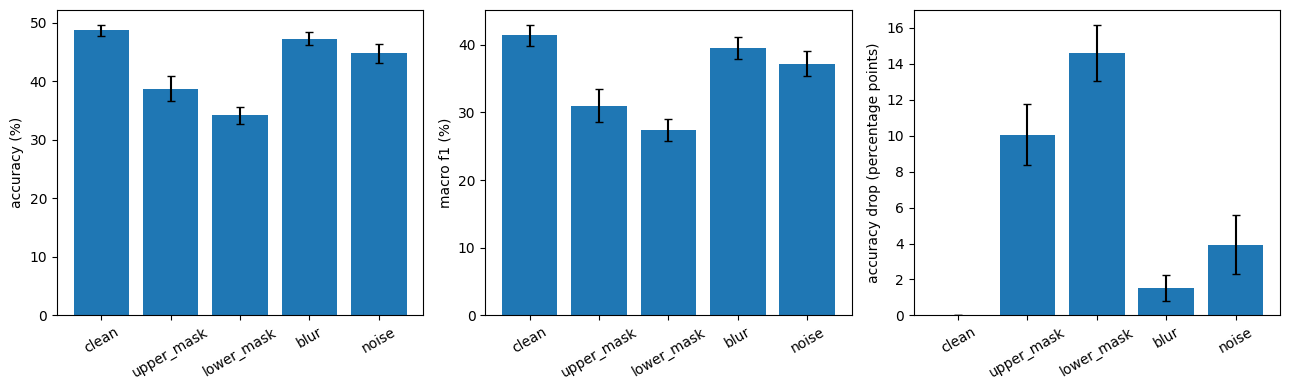

 condition  accuracy_mean  accuracy_sd  macro_precision_mean  macro_precision_sd  macro_recall_mean  macro_recall_sd  macro_f1_mean  macro_f1_sd  accuracy_drop_mean  accuracy_drop_sd  macro_f1_drop_mean  macro_f1_drop_sd
     clean       0.487849     0.009414              0.449825            0.038292           0.423923         0.010887       0.413767     0.015959            0.000000          0.000000            0.000000          0.000000
upper_mask       0.387346     0.021274              0.390508            0.026797           0.329323         0.019597       0.310096     0.023746            0.100503          0.016882            0.103672          0.020361
lower_mask       0.341883     0.014789              0.297197            0.025052           0.293763         0.013699       0.273872     0.016824            0.145966          0.015775            0.139895          0.018622
      blur       0.472649     0.011132              0.422271            0.023046           0.408003         0.011379

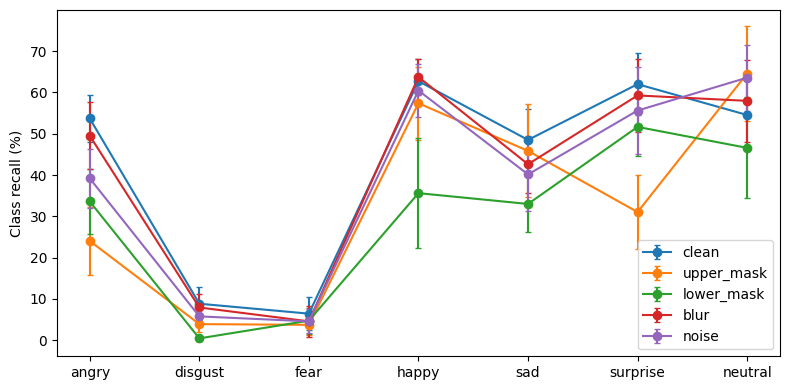

Selected learning rates: {1e-05: 0, 0.0001: 0, 0.001: 10}
Review INNER scores and revise the candidate range; do not force the middle rate or tune on outer tests.


In [9]:
import matplotlib.pyplot as plt

# Summarise the saved outer-fold predictions
predictions = pd.read_csv(OUTPUT/'predictions.csv')
results, class_results = [], []
confusions = {c: np.zeros((7, 7), dtype=int) for c in CONDITIONS}
# Calculate paired drops relative to clean predictions
for fold in range(1, 11):
    held_out = predictions[predictions['outer_fold'] == fold]
    clean = held_out[held_out['condition'] == 'clean']
    clean_scores = metrics(clean['y_true'], clean['y_pred'])[0]
    for condition in CONDITIONS:
        selected = held_out[held_out['condition'] == condition]
        scores, matrix, class_scores = metrics(selected['y_true'], selected['y_pred'])
        results.append(dict(outer_fold=fold, condition=condition,
            learning_rate=selected['learning_rate'].iloc[0], **scores,
            accuracy_drop=clean_scores['accuracy']-scores['accuracy'],
            macro_f1_drop=clean_scores['macro_f1']-scores['macro_f1']))
        confusions[condition] += matrix
        for i, name in enumerate(CLASS_NAMES):
            class_results.append(dict(outer_fold=fold, condition=condition, class_name=name,
                precision=class_scores[i, 0], recall=class_scores[i, 1], f1=class_scores[i, 2]))
fold_results = pd.DataFrame(results)
class_results = pd.DataFrame(class_results)
fold_results.to_csv(OUTPUT/'fold_results.csv', index=False)
class_results.to_csv(OUTPUT/'classwise_results.csv', index=False)
for condition, matrix in confusions.items():
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT/f'confusion_{condition}.csv')

# Get the mean and sample SD across all outer folds
summary = []
for condition in CONDITIONS:
    row = dict(condition=condition)
    selected = fold_results[fold_results['condition'] == condition]
    for metric in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'accuracy_drop', 'macro_f1_drop']:
        values = selected[metric].to_numpy()
        row[metric+'_mean'], row[metric+'_sd'] = np.mean(values), np.std(values, ddof=1)
    summary.append(row)
summary = pd.DataFrame(summary)
summary.to_csv(OUTPUT/'condition_summary.csv', index=False)
figure, axes = plt.subplots(1, 3, figsize=(13, 4))
for axis, metric in zip(axes, ['accuracy', 'macro_f1', 'accuracy_drop']):
    axis.bar(CONDITIONS, 100*summary[metric+'_mean'], yerr=100*summary[metric+'_sd'], capsize=3)
    axis.tick_params(axis='x', rotation=30)
    axis.set_ylabel(metric.replace('_', ' ') + (' (percentage points)' if 'drop' in metric else ' (%)'))
figure.tight_layout()
figure.savefig(OUTPUT/'results_with_sd.png', dpi=200)
plt.show()
print(summary.to_string(index=False))

# Recall for each expression class
figure, axis = plt.subplots(figsize=(8, 4))
for condition in CONDITIONS:
    values = np.array([class_results[(class_results['condition'] == condition) &
        (class_results['class_name'] == name)]['recall'].to_numpy() for name in CLASS_NAMES])
    axis.errorbar(range(7), 100*values.mean(1), yerr=100*values.std(1, ddof=1),
                  marker='o', capsize=2, label=condition)
axis.set_xticks(range(7), CLASS_NAMES)
axis.set_ylabel('Class recall (%)')
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT/'class_recall_with_sd.png', dpi=200)
plt.show()

# These counts use the initial grid
choices = fold_results.loc[fold_results['condition'] == 'clean', 'learning_rate'].tolist()
counts = [choices.count(rate) for rate in LEARNING_RATES]
print('Selected learning rates:', dict(zip(LEARNING_RATES, counts)))
if counts[1] <= max(counts[0], counts[2]):
    print('Review INNER scores and revise the candidate range; do not force the middle rate or tune on outer tests.')
    # 0.01 was added above after this
